# ICTSahayi: fine-tune and evaluate on Kaggle

Before running: in the notebook settings, turn on **GPU** (T4 or P100) and **Internet**. Then *Run all*.

At the end, download `ictsahayi_results.zip` from the Output panel, unzip it into your local copy of the repo, and commit the `results/` folder and `static/loss-plot.*` files.

In [1]:
!git clone -q https://github.com/cksajil/ICTSahayi.git
%cd ICTSahayi
!git log --oneline -3

/kaggle/working/ICTSahayi
451bcd3 (HEAD -> main, origin/main, origin/HEAD) Merge pull request #1 from cksajil/fix-finetune-and-eval
805d1c9 (origin/fix-finetune-and-eval) Fix fine-tuning bug and add evaluation
5e1b552 added data


In [2]:
# TensorFlow, PyTorch, NumPy and Matplotlib are already installed on Kaggle
!pip install -q tiktoken

## 1. Fine-tune
Watch the line *Loss before fine-tuning*: it should be roughly 3 to 4.5. A value near 10 would mean the pretrained weights did not load, and the script stops.

In [3]:
!python finetune.py

2026-10-27 12:05:59.349646: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1793102759.628967      60 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1793102759.716106      60 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1793102760.476143      60 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1793102760.476202      60 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1793102760.476210      60 computation_placer.cc:177] computation placer alr

## 2. Evaluate
Compares a retrieval baseline, base GPT-2 and the fine-tuned model on the held-out and reworded questions.

In [4]:
!python evaluate.py

2026-10-27 12:11:35.032057: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1793103095.049014      82 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1793103095.054702      82 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1793103095.069946      82 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1793103095.069982      82 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1793103095.069986      82 computation_placer.cc:177] computation placer alr

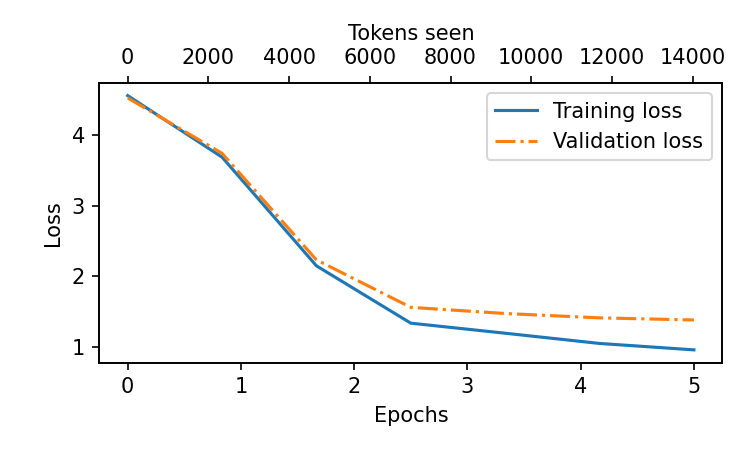

# Evaluation results

Score: mean ROUGE-L F1 against the reference answer (0 to 1). 'close' = share of answers with ROUGE-L >= 0.5.

| System | held-out (n=6) | reworded (seen) (n=16) | reworded (unseen) (n=4) |
| --- | --- | --- | --- |
| Retrieval baseline (no model) | 0.13 (0% close) | 0.31 (25% close) | 0.14 (0% close) |
| GPT-2 base (not fine-tuned) | 0.15 (0% close) | 0.09 (0% close) | 0.13 (0% close) |
| GPT-2 fine-tuned | 0.18 (0% close) | 0.21 (6% close) | 0.26 (0% close) |


In [5]:
from IPython.display import Image, Markdown, display
display(Image('static/loss-plot.png'))
display(Markdown(open('results/eval_summary.md').read()))

## 3. Try some answers

In [6]:
!python infer.py
!python infer.py --question "Can I pay the course fee in instalments?"

Q:         What is the deferral policy at ICTAK?
Expected:  Learners can defer to another batch with a fee, within six months of the original batch’s closing.
Model:     The deferral policy is based on the academic performance of ICTAK students.
------------------------------------------------------------
Q:         Where is the headquarters of ICT Academy of Kerala located?
Expected:  The headquarters of ICT Academy of Kerala is at Thejaswini Building, Technopark Campus, Thiruvananthapuram, Kerala, India.
Model:     The ICT Academy of Kerala is located in Kerala, but is not yet open to the general public.
------------------------------------------------------------
Q:         Are scholarships available for women candidates?
Expected:  Yes, additional scholarship benefits may be available for women candidates in certain programs.
Model:     Scholarships are available for women candidates who complete the required coursework.
------------------------------------------------------------


## 4. Package the results to commit

In [7]:
!zip -r /kaggle/working/ictsahayi_results.zip results static/loss-plot.png static/loss-plot.pdf
print('Download ictsahayi_results.zip from the Output panel.')

  adding: results/ (stored 0%)
  adding: results/train_log.json (deflated 42%)
  adding: results/eval_summary.md (deflated 48%)
  adding: results/eval_results.json (deflated 88%)
  adding: static/loss-plot.png (deflated 8%)
  adding: static/loss-plot.pdf (deflated 31%)
Download ictsahayi_results.zip from the Output panel.
